In [2]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import pickle
import time
from deep_bsde_model import DeepBSDE
from sampling import call_payoff, eu_call_price, basket_call_payoff, y0_init
from finite_diff_schemes import cn_basket_prices 
from bsde_batch import load_one, dims, CONFIG, build_model
from functools import partial
import os 

r = 0.05  # interest rate
sigma = 0.2  # volatility
T = 1.0  # maturity<
N = 30 #standard time discretization
K = 100.0
seed = 0

We create a test comparing deep BSDE against the closed form BS call price

In [ ]:
#we train the model for multiple strikes
K = np.linspace(50,150, 5)
models = []
for k in K:
    print(f'strike price is {k}')
    mu_fn = lambda t, x: r * x
    f_fn = lambda t, x, y, z: -r * y
    sigma_const = tf.constant(sigma, dtype=tf.float32)
    sigma_fn = lambda t, x: sigma_const * x
    payoff_fn = partial(call_payoff, K=k)

    X_low, X_high = 80,120 
    model = DeepBSDE(d=1, N=N, X0_low=X_low, X0_high=X_high, mu_fn=mu_fn, sigma_fn=sigma_fn, f_fn=f_fn , 
                     payoff_fn=payoff_fn, num_units=10, num_hidden_layers=3, verbose=2
                    )
    model.train(num_epochs= 2000, batch_size=256)
    print('-'*50)
    print(f'model for k={k} finnished training')
    models.append(model)

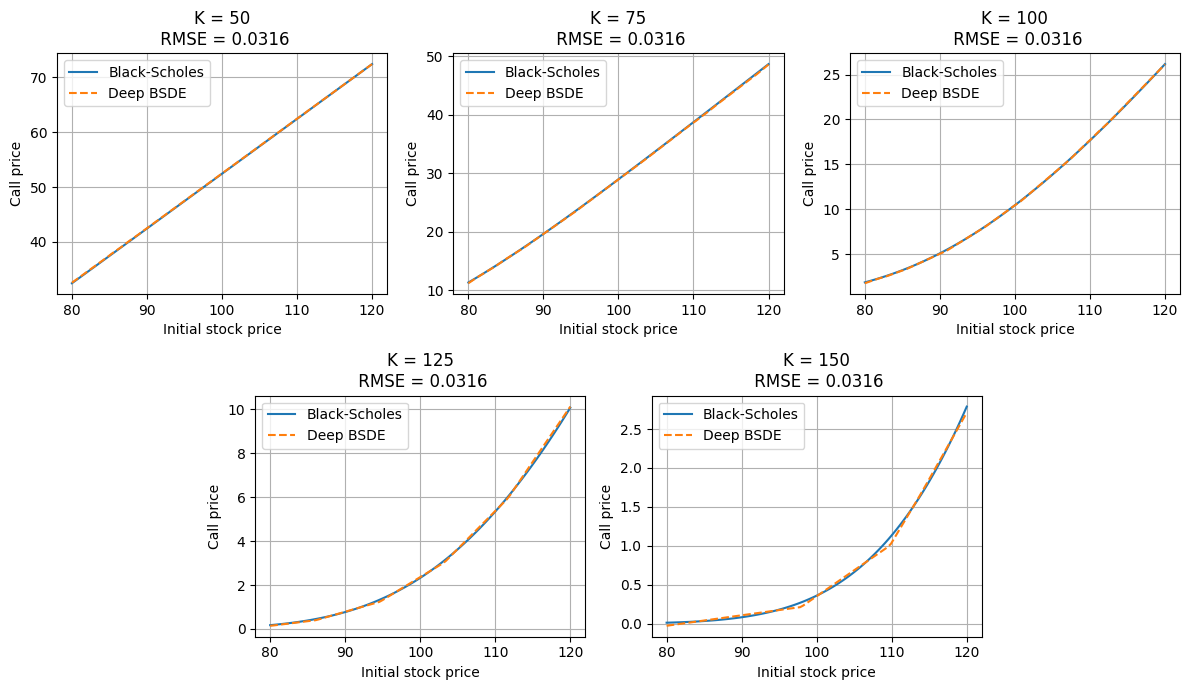

In [29]:
fig = plt.figure(figsize=(12, 7))
gs = fig.add_gridspec(2, 6)
S0_points = np.linspace(80, 120, 100)

axes = [
    fig.add_subplot(gs[0, 0:2]),
    fig.add_subplot(gs[0, 2:4]),
    fig.add_subplot(gs[0, 4:6]),
    fig.add_subplot(gs[1, 1:3]),
    fig.add_subplot(gs[1, 3:5])
]

for i, (k, model) in enumerate(zip(K, models)):

    bsde_prices = model.predict_price(
        S0_points.reshape(-1, 1)
    ).numpy()

    bs_prices = eu_call_price(
        S0_points, k, T, r, sigma
    )

    axes[i].plot(S0_points, bs_prices, label="Black-Scholes")
    axes[i].plot(S0_points, bsde_prices, "--", label="Deep BSDE")

    axes[i].set_title(f"K = {k:.0f}\n RMSE = {rmse:.4f}")
    axes[i].set_xlabel("Initial stock price")
    axes[i].set_ylabel("Call price")
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()

fig.savefig("images/deep_bsde_vs_bs_d1.pdf", bbox_inches="tight")
plt.show()

In [59]:
K, T, r = CONFIG["K"], CONFIG["T"], CONFIG["r"]
M, mc_batch = 200, 100_000
seeds = np.arange(10)

maes, rmses = [], []
mae_stds, rmse_stds = [], []
mc_maes, mc_rmses = [], []

all_times = []
inference_times = []

for d in dims:
    times = []
    inferences = []
    print(f"Evaluating d={d}")

    rng = np.random.default_rng(d)
    X_test = rng.uniform(80, 120, size=(M, d)).astype(np.float32)

    corr = np.full((d, d), CONFIG["rho"], dtype=np.float32)
    np.fill_diagonal(corr, 1.0)


    mc_t0 = time.time()
    mc_results = np.array([
        [float(v) for v in y0_init(
            x, K, T, r=r, sigma=CONFIG["sigma"],
            weights=np.ones(d, dtype=np.float32) / d,
            corr=corr, batch_size=mc_batch
        )]
        for x in X_test
    ])
    mc_time = time.time() - mc_t0 
    mc_prices, mc_errors = mc_results.T

    mc_maes.append(np.sqrt(2 / np.pi) * np.mean(mc_errors))
    mc_rmses.append(np.sqrt(np.mean(mc_errors**2)))

    seed_maes, seed_rmses = [], []

    for seed in seeds:
        print(f'seed: {seed}')
        model, runtime = load_one(seed=seed, d=d)

        inf_t0 = time.perf_counter()
        predictions = model.predict_price(X_test).numpy()
        inference = time.perf_counter() - inf_t0
        errors = predictions - mc_prices

        times.append(runtime)
        seed_maes.append(np.mean(np.abs(errors)))
        seed_rmses.append(np.sqrt(np.mean(errors**2)))
        inferences.append(inference)
    
    inference_times.append(inferences)
    all_times.append((times, mc_time))
    maes.append(np.mean(seed_maes))
    rmses.append(np.mean(seed_rmses))

    mae_stds.append(np.std(seed_maes))
    rmse_stds.append(np.std(seed_rmses))


Evaluating d=2
seed: 0
seed: 1
seed: 2
seed: 3
seed: 4
seed: 5
seed: 6
seed: 7
seed: 8
seed: 9
Evaluating d=3
seed: 0
seed: 1
seed: 2
seed: 3
seed: 4
seed: 5
seed: 6
seed: 7
seed: 8
seed: 9
Evaluating d=5
seed: 0
seed: 1
seed: 2
seed: 3
seed: 4
seed: 5
seed: 6
seed: 7
seed: 8
seed: 9
Evaluating d=10
seed: 0
seed: 1
seed: 2
seed: 3
seed: 4
seed: 5
seed: 6
seed: 7
seed: 8
seed: 9
Evaluating d=20
seed: 0
seed: 1
seed: 2
seed: 3
seed: 4
seed: 5
seed: 6
seed: 7
seed: 8
seed: 9
Evaluating d=50
seed: 0
seed: 1
seed: 2
seed: 3
seed: 4
seed: 5
seed: 6
seed: 7
seed: 8
seed: 9
Evaluating d=100
seed: 0
seed: 1
seed: 2
seed: 3
seed: 4
seed: 5
seed: 6
seed: 7
seed: 8
seed: 9


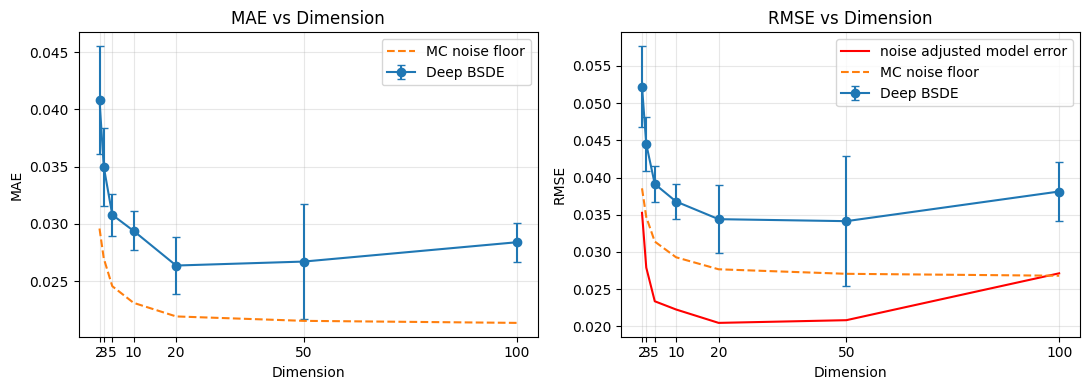

In [60]:
noise_adjusted_error = np.sqrt(
    np.maximum(0, np.asarray(rmses)**2 - np.asarray(mc_rmses)**2)
) 

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].errorbar(dims, maes, yerr=mae_stds, fmt="o-", capsize=3, label="Deep BSDE")
axes[0].set(xlabel="Dimension", ylabel="MAE", title="MAE vs Dimension")


axes[1].errorbar(dims, rmses, yerr=rmse_stds, fmt="o-", capsize=3, label="Deep BSDE")
axes[1].plot(dims, noise_adjusted_error, color='red', label='noise adjusted model error')
axes[1].set(xlabel="Dimension", ylabel="RMSE", title="RMSE vs Dimension")

axes[0].plot(dims, mc_maes, "--", label="MC noise floor")
axes[1].plot(dims, mc_rmses, "--", label="MC noise floor")

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.set_xticks(dims)
    ax.legend()

plt.tight_layout()
fig.savefig(fname='images/accuracy_vs_dim.pdf', bbox_inches='tight')
plt.show()

In [61]:
print("Inference times shape:", inference_times.shape)
print("Mean inference times:", mean_inf)
print("Standard deviations:", std_inf)
print("Finite:", np.isfinite(mean_inf))

AttributeError: 'list' object has no attribute 'shape'

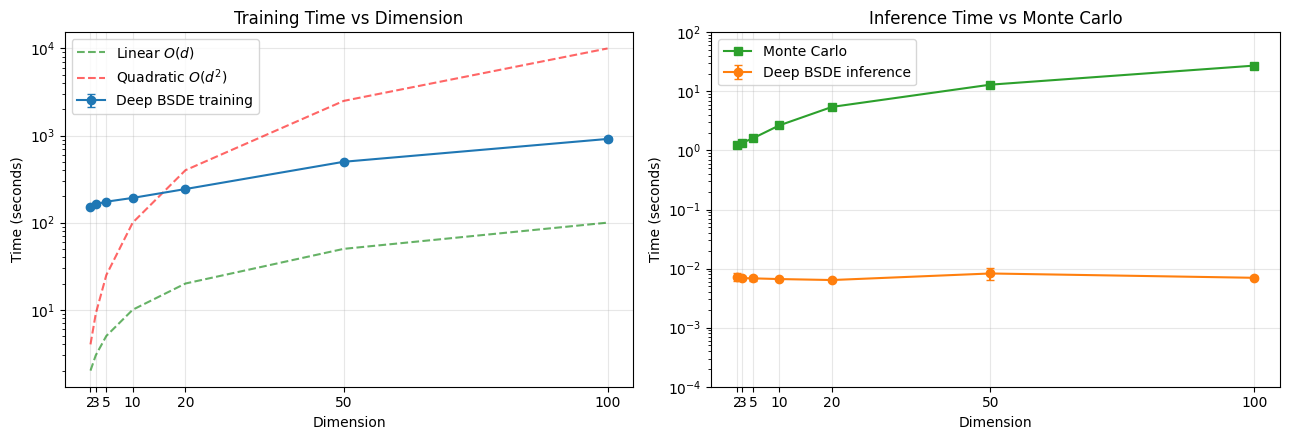

In [66]:
inference_times =np.array(inference_times)
train_times = np.array([t[0] for t in all_times])
mc_times = np.array([t[1] for t in all_times])
inference_times = np.array(inference_times)

mean_times, std_times = train_times.mean(axis=1), train_times.std(axis=1)

mean_inf, std_inf = inference_times.mean(axis=1), inference_times.std(axis=1) 

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].errorbar(dims, mean_times, yerr=std_times, fmt="o-", capsize=3,
    color="tab:blue", label="Deep BSDE training")

axes[0].plot(dims, dims, "--",
    color="green", alpha=0.6, label=r"Linear $O(d)$")

axes[0].plot(dims, np.asarray(dims)**2, "--",
    color="red", alpha=0.6, label=r"Quadratic $O(d^2)$")

axes[0].set(xlabel="Dimension", ylabel="Time (seconds)", title="Training Time vs Dimension")
axes[0].set_yscale("log")
axes[0].set_xticks(dims)
axes[0].grid(True, alpha=0.3)
axes[0].legend()


axes[1].errorbar(dims, mean_inf, yerr=std_inf, fmt="o-", capsize=3,
    color="tab:orange", label="Deep BSDE inference")

axes[1].plot(dims, mc_times, "s-", color="tab:green",
    label="Monte Carlo")
axes[1].set_yscale("log")
axes[1].set_ylim(1e-4, 1e2)
axes[1].set(xlabel="Dimension", ylabel="Time (seconds)", title="Inference Time vs Monte Carlo")
axes[1].set_xticks(dims)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()

fig.savefig(
    "images/deep_bsde_time_vs_dim.pdf",
    bbox_inches="tight"
)

plt.show()

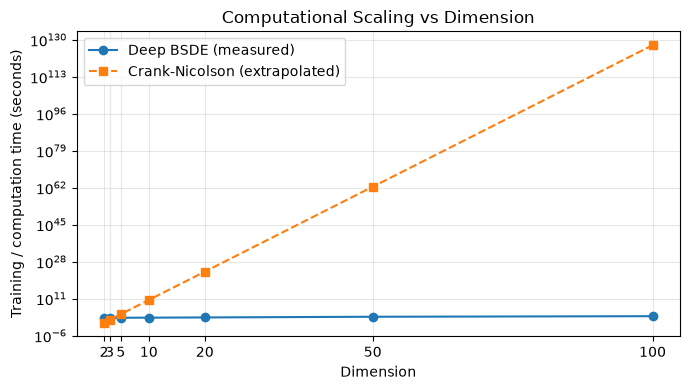

In [13]:
M = 20
T_cn_2 = 1.0  # Replace with measured CN runtime at d=2

cn_times = T_cn_2 * np.float64(M) ** (np.array(dims) - 2)

plt.figure(figsize=(7, 4))

plt.plot(dims, mean_times, "o-", label="Deep BSDE (measured)")
plt.plot(dims, cn_times, "s--", label="Crank-Nicolson (extrapolated)")

plt.yscale("log")
plt.xlabel("Dimension")
plt.ylabel("Training / computation time (seconds)")
plt.title("Computational Scaling vs Dimension")
plt.xticks(dims)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
dims = [1, 2, 3, 4]
K, T, r = CONFIG["K"], CONFIG["T"], CONFIG["r"]

M_grid = 16
N_time = 100
n_test = 200
mc_batch = 100_000

bsde_maes, bsde_rmses, bsde_times = [], [], []
cn_maes, cn_rmses, cn_times = [], [], []
mc_maes, mc_rmses = [], []

for d in dims:
    print(f"Evaluating d={d}")

    corr = np.full((d, d), CONFIG["rho"], dtype=np.float32)
    np.fill_diagonal(corr, 1.0)

    # 1. Train a fresh Deep BSDE
    model = build_model(d, config=CONFIG, verbose=0)

    t0 = time.perf_counter()
    model.train(
        num_epochs=CONFIG["num_epochs"],
        batch_size=CONFIG["batch_size"],
        learning_rate=CONFIG["learning_rate"]
    )
    bsde_times.append(time.perf_counter() - t0)

    # 2. Generate test points
    rng = np.random.default_rng(d)
    X_test = rng.uniform(80, 120, size=(n_test, d)).astype(np.float32)

    # 3. Monte Carlo reference
    mc_results = np.array([
        [float(v) for v in y0_init(x, K, T, r=r, sigma=CONFIG["sigma"],
            weights=np.ones(d, dtype=np.float32) / d, corr=corr, batch_size=mc_batch
        )]for x in X_test])

    mc_prices, mc_errors = mc_results.T

    # 4. Deep BSDE predictions
    bsde_prices = model.predict_price(X_test).numpy().reshape(-1)

    # 5. Crank-Nicolson predictions
    t0 = time.perf_counter()
    cn_prices = cn_basket_prices(S0_points=X_test, K=K, T=T, r=r,
        sigma=CONFIG["sigma"], corr=corr, M=M_grid, N_time=N_time)
    cn_times.append(time.perf_counter() - t0)

    # 6. Errors
    bsde_errors = bsde_prices - mc_prices
    cn_errors = cn_prices - mc_prices

    bsde_maes.append(np.mean(np.abs(bsde_errors)))
    bsde_rmses.append(np.sqrt(np.mean(bsde_errors**2)))
    cn_maes.append(np.mean(np.abs(cn_errors)))
    cn_rmses.append(np.sqrt(np.mean(cn_errors**2)))
    mc_maes.append(np.sqrt(2 / np.pi) * np.mean(mc_errors))
    mc_rmses.append(np.sqrt(np.mean(mc_errors**2)))

    print(
        f"BSDE MAE={bsde_maes[-1]:.5f}, "
        f"CN MAE={cn_maes[-1]:.5f}, "
        f"BSDE time={bsde_times[-1]:.2f}s, "
        f"CN time={cn_times[-1]:.2f}s"
    )

# 7. Plot everything
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(dims, bsde_maes, "o-", label="Deep BSDE")
axes[0].plot(dims, cn_maes, "s-", label="Crank-Nicolson")
axes[0].plot(dims, mc_maes, "--", label="MC noise floor")
axes[0].set(xlabel="Dimension", ylabel="MAE", title="MAE vs Dimension")

axes[1].plot(dims, bsde_rmses, "o-", label="Deep BSDE")
axes[1].plot(dims, cn_rmses, "s-", label="Crank-Nicolson")
axes[1].plot(dims, mc_rmses, "--", label="MC noise floor")
axes[1].set(xlabel="Dimension", ylabel="RMSE", title="RMSE vs Dimension")

axes[2].plot(dims, bsde_times, "o-", label="Deep BSDE")
axes[2].plot(dims, cn_times, "s-", label="Crank-Nicolson")
axes[2].set_yscale("log")
axes[2].set(
    xlabel="Dimension",
    ylabel="Runtime (seconds)",
    title="Runtime vs Dimension"
)

for ax in axes:
    ax.set_xticks(dims)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

Evaluating d=1
Built: True
BSDE MAE=0.05832, CN MAE=0.72058, BSDE time=93.42s, CN time=0.00s
Evaluating d=2
Built: True
BSDE MAE=0.03753, CN MAE=0.19918, BSDE time=97.04s, CN time=0.01s
Evaluating d=3
Built: True
BSDE MAE=0.03276, CN MAE=0.25546, BSDE time=96.79s, CN time=0.62s
Evaluating d=4
Built: True
